# Monte Carlo Simulation of NVIDIA Stock Prices

This project uses historical NVIDIA (NVDA) stock-price data to simulate possible future price paths using the Monte Carlo method and Geometric Brownian Motion (GBM).

The simulation is for educational purposes only and does not provide investment advice.

1. Importing Libraries

In this section, the required Python libraries are imported.
- yfinance downloads historical market data.
- pandas manages the dataset.
- numpy performs numerical calculations.
- matplotlib creates visualizations.

In [34]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import yfinance as yf

In [35]:
NUM_SIMULATIONS = 10_000 # 10k possible outcomes  
NUM_TIME_STEPS = 252 # 1 per day for 1 year
INITIAL_TIME = 0
FINAL_TIME = 252

2. Downloading Historical NVDA Data

Historical adjusted closing-price data for NVIDIA (NVDA) are downloaded for the previous five years.

The adjusted closing price is used because it accounts for stock splits and other corporate actions, making the historical series more consistent.

In [36]:
data = yf.download("NVDA", period="5y", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [37]:
close_prices = data["Close"].squeeze()
log_returns = np.log(close_prices / close_prices.shift(1)).dropna()

3. Estimating Historical Return and Volatility

Daily logarithmic returns are calculated from historical closing prices.

The average daily log-return and its standard deviation are then annualized using 252 trading days per year:

These values represent the estimated annual drift and volatility used in the simulation.

In [38]:
annualized_mean = log_returns.mean() * 252
annualized_volatility = log_returns.std() * np.sqrt(252)

In [39]:
INITIAL_PRICE = close_prices.iloc[-1]

In [40]:
print(f"Annualized mean: {annualized_mean:.2%}")
print(f"Annualized volatility: {annualized_volatility:.2%}")
print(f"Initial price: ${INITIAL_PRICE:.2f}")

Annualized mean: 34.58%
Annualized volatility: 51.54%
Initial price: $168.89


In [41]:
rng = np.random.default_rng(42) # Random number generator 

In [42]:
random_shocks = rng.standard_normal(
    (NUM_SIMULATIONS, NUM_TIME_STEPS)
)

4. Geometric Brownian Motion Model

The future stock-price paths are simulated with the Geometric Brownian Motion model.
The model ensures that simulated prices remain positive.

In [43]:
delta_t = 1/252 
random_component = annualized_volatility * np.sqrt(delta_t) * random_shocks 
drift_component = (annualized_mean - (0.5 * (annualized_volatility) ** 2)) * delta_t

In [44]:
growth_factors = np.exp(drift_component + random_component)
simulated_prices = INITIAL_PRICE * np.cumprod(growth_factors, axis=1)

In [45]:
print(f"Matrix dimensions: {simulated_prices.shape}")
print(f"Check for infinite values: {np.sum(np.isinf(simulated_prices))}")
print(f"Terminal price statistics: \n Mean: {np.mean(simulated_prices[:, -1])} \n Median: {np.median(simulated_prices[:, -1])} \n Min: {np.min(simulated_prices[:, -1])} \n Max: {np.max(simulated_prices[:, -1])}")

Matrix dimensions: (10000, 252)
Check for infinite values: 0
Terminal price statistics: 
 Mean: 239.92898520504124 
 Median: 209.44165609387514 
 Min: 13.403771816476645 
 Max: 1301.9317240489063


5. Visualizing Simulated Price Paths

The model generates 10,000 possible NVIDIA price paths over one trading year, equal to 252 trading days.

Each path represents one possible future scenario based on historical average return and volatility.

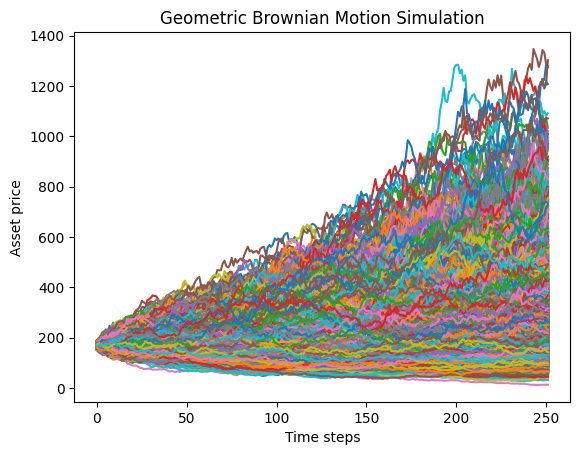

In [46]:
for simulation in simulated_prices:
  plt.plot(np.arange(0, 252), simulation)
  
plt.xlabel("Time steps")
plt.ylabel("Asset price")
plt.title("Geometric Brownian Motion Simulation")
plt.show()  

6. Simulated Price Paths Chart

The chart shows all simulated stock-price paths in gray.

The red line represents the average simulated price at each time step. It summarizes the expected price path across all simulations.

The wide dispersion of paths reflects the uncertainty associated with stock-price movements.

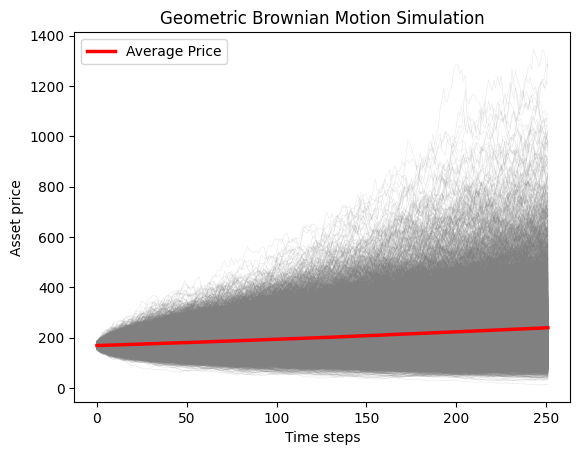

In [47]:
average_prices = np.mean(simulated_prices, axis=0)

for simulation in simulated_prices:
    plt.plot(simulation, color="gray", alpha=0.15, linewidth=0.5)

plt.plot(average_prices, color="red", linewidth=2.5, label="Average Price")

plt.xlabel("Time steps")
plt.ylabel("Asset price")
plt.title("Geometric Brownian Motion Simulation")
plt.legend()
plt.show()

7. Distribution of Terminal Prices

The histogram shows the distribution of the simulated NVIDIA prices at the end of the one-year period.

The distribution is positively skewed: most simulated terminal prices are concentrated in a central range, while a small number of paths produce very high prices.

This right-skewed shape is a typical characteristic of Geometric Brownian Motion and the lognormal distribution.

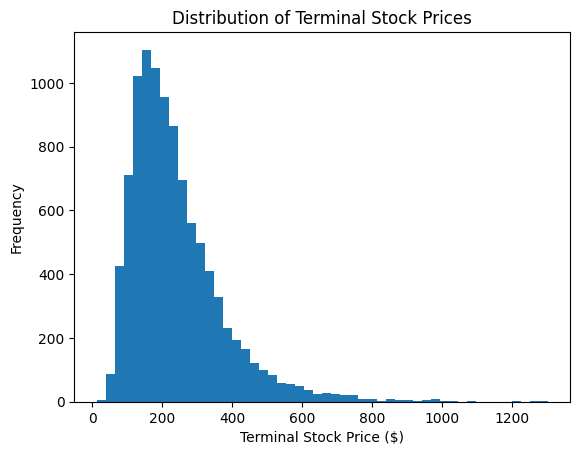

In [48]:
plt.hist(simulated_prices[:, -1], bins=50)

plt.xlabel("Terminal Stock Price ($)")
plt.ylabel("Frequency")
plt.title("Distribution of Terminal Stock Prices")

plt.show()

8. Conclusion

This project estimates possible future NVIDIA stock prices using five years of historical data and a Geometric Brownian Motion model.

The simulation does not predict the future with certainty. Instead, it shows a range of plausible scenarios based on historical return and volatility.

The results demonstrate how uncertainty and volatility can strongly affect the distribution of future stock prices.